# YOLO Model Comparison – Nano vs. Medium vs. Large

This notebook puts all three trained dog-detection models side by side:
`nano` (`train_yolo_nano.py`), `medium` (`train_yolo_medium.py`), and
`large` (`train_yolo_large.py`). Every table, plot, and printed output below is
followed by a short markdown block explaining what it shows and what it means.

**Note on `large`:** that run was trained on a different machine (an HPC cluster),
so its results are only included here if the run folder
(`runs/detect/dogs_large/` with `weights/best.pt`, `results.csv`, `args.yaml`) has
been copied into this project locally. If it's missing, every cell below still runs
and simply compares `nano` vs. `medium` — the moment the `dogs_large` folder is
added, re-running this notebook will pull it into every comparison automatically.


## Dataset & Models Overview

### Train / Val / Test Split
240 annotated frames total, split **by time** (not randomly) to avoid temporal
autocorrelation bias — dogs often lie still for minutes, so a random split would leak
near-identical, temporally adjacent frames between train and test.

| Split | Images | Share | Time range | Contains |
|-------|--------|-------|------------|----------|
| train | 128 | 53.3% | 0.00s – 478.46s (0–8 min) | part_01 (full) + start of part_02 |
| val   | 33  | 13.8% | 482.26s – 599.98s (~8–10 min) | rest of part_02 |
| test  | 79  | 32.9% | 603.78s – 899.96s (10–15 min) | part_03 (full) |

### Models Compared
- **nano** (`train_yolo_nano.py`, `yolov8n.pt`) — 3.0M parameters, 80 epochs,
  batch size 16, ~0.6h training time on CPU.
- **medium** (`train_yolo_medium.py`, `yolov8m.pt`) — 25.9M parameters, 50 epochs,
  batch size 4, 2 dataloader workers, no image caching (reduced to fit WSL2's
  ~7GB RAM limit), ~2.0h training time on CPU.
- **large** (`train_yolo_large.py`, `yolov8l.pt`) — 43.7M parameters, 50 epochs,
  AutoBatch, 8 dataloader workers, image caching enabled — configured for a
  more powerful machine than nano/medium were trained on. Actual training
  duration and metrics are read from its `results.csv`/`args.yaml` below, not
  assumed.


---
## 0. Setup


In [1]:
from pathlib import Path
import yaml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.patches as mpatches
import cv2
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False


In [2]:
PROJECT_DIR = Path(".")
RUN_BASE    = PROJECT_DIR / "runs" / "detect"
DATA_YAML   = PROJECT_DIR / "data" / "yolo_dataset" / "data.yaml"

RUN_NAMES = {"nano": "dogs_nano", "medium": "dogs_medium", "large": "dogs_large"}
MODEL_COLORS = {"nano": "#3498db", "medium": "#9b59b6", "large": "#e67e22"}

with open(DATA_YAML) as f:
    data_cfg = yaml.safe_load(f)

split_counts = {}
for split in ["train", "val", "test"]:
    split_dir = Path(data_cfg["path"]) / data_cfg[split]
    split_counts[split] = len(list(split_dir.glob("*.jpg"))) if split_dir.exists() else 0

for label, run_name in RUN_NAMES.items():
    run_dir = RUN_BASE / run_name
    status = "found" if (run_dir / "weights" / "best.pt").exists() else "NOT found locally"
    print(f"  {label:<8} ({run_name:<12}): {status}  [{run_dir}]")


  nano     (dogs_nano   ): found  [runs/detect/dogs_nano]
  medium   (dogs_medium ): found  [runs/detect/dogs_medium]
  large    (dogs_large  ): NOT found locally  [runs/detect/dogs_large]


**What this shows:** whether each model's run folder (weights + training log) is
actually present on this machine. `nano` and `medium` were trained locally and
should always show up; `large` only shows up once its `runs/detect/dogs_large/`
folder has been copied over from the machine it was trained on.


---
## 1. Collect Metrics for Every Available Run


In [3]:
comparison_rows = {}
run_dfs = {}
loaded_models = {}

for label, run_name in RUN_NAMES.items():
    run_dir = RUN_BASE / run_name
    weights_path = run_dir / "weights" / "best.pt"
    results_csv  = run_dir / "results.csv"
    args_yaml    = run_dir / "args.yaml"

    if not (weights_path.exists() and results_csv.exists()):
        print(f"  {label} ({run_name}): run not found or incomplete – skipped.")
        continue

    run_args = {}
    if args_yaml.exists():
        with open(args_yaml) as f:
            run_args = yaml.safe_load(f)

    run_df = pd.read_csv(results_csv)
    run_df.columns = run_df.columns.str.strip()
    run_dfs[label] = run_df
    run_best_idx = run_df["metrics/mAP50(B)"].idxmax()

    model = YOLO(str(weights_path))
    loaded_models[label] = model
    n_params = sum(p.numel() for p in model.model.parameters())

    train_time_h = run_df["time"].iloc[-1] / 3600 if "time" in run_df.columns else float("nan")

    row = {
        "Model (weights)": run_args.get("model", "unknown"),
        "Parameters": n_params,
        "Epochs trained": int(run_df["epoch"].max()),
        "Best epoch (mAP50)": int(run_df.loc[run_best_idx, "epoch"]),
        "Training duration (h)": round(train_time_h, 2),
    }

    for split in ["val", "test"]:
        split_dir = Path(data_cfg["path"]) / data_cfg[split]
        if not split_dir.exists() or not any(split_dir.glob("*.jpg")):
            continue
        metrics = model.val(data=str(DATA_YAML), split=split, verbose=False)
        row[f"Precision ({split})"] = round(float(metrics.box.mp), 4)
        row[f"Recall ({split})"]    = round(float(metrics.box.mr), 4)
        row[f"mAP@50 ({split})"]    = round(float(metrics.box.map50), 4)
        row[f"mAP@50-95 ({split})"] = round(float(metrics.box.map), 4)

    comparison_rows[label] = row

assert comparison_rows, "None of dogs_nano / dogs_medium / dogs_large were found."
AVAILABLE_MODELS = list(comparison_rows.keys())
print(f"\nModels included in this comparison: {AVAILABLE_MODELS}")


Ultralytics 8.4.67 🚀 Python-3.11.15 torch-2.12.0+cu130 CPU (Intel Core Ultra 5 226V)


Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access ✅ (ping: 11.3±2.8 ms, read: 7.3±1.2 MB/s, size: 162.1 KB)


val: Scanning /mnt/c/Users/linap/OneDrive/Documents/Master/SoSe2026/deepLearning/git_project/dogs-tracking/data/yolo_dataset/labels/val.cache... 33 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 33/33 3.6Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 33% ━━━━──────── 1/3 6.6s/it 2.0s<13.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 66% ━━━━━━━━──── 2/3 3.1s/it 3.4s<3.1s

... (33 outputs left out)

                   all         79        211      0.915      0.512      0.691      0.293


Speed: 1.8ms preprocess, 350.8ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to /mnt/c/Users/linap/OneDrive/Documents/Master/SoSe2026/deepLearning/git_project/dogs-tracking/runs/detect/val-10


  large (dogs_large): run not found or incomplete – skipped.

Models included in this comparison: ['nano', 'medium']


In [4]:
# ultralytics' model.val() temporarily switches the matplotlib backend for its own
# plots (confusion matrix, PR curve) and restoring it afterwards doesn't fully
# re-register Jupyter's inline figure capture -- without this, every plt.show()
# below would silently stop rendering images. Re-enabling it explicitly fixes that.
get_ipython().run_line_magic('matplotlib', 'inline')


**What this does:** for every model whose run folder exists, it loads `best.pt`,
reads its training log (`results.csv`/`args.yaml`), and runs a fresh evaluation on
the val and test splits (not just re-reading numbers YOLO logged during training —
this re-computes them directly from the current best weights, so all three models
are scored under identical, current conditions). `AVAILABLE_MODELS` printed above
is the actual list used in every section below — if `large` is missing, it's simply
excluded rather than causing an error.


---
## 2. Comparison Table


In [5]:
df_compare = pd.DataFrame(comparison_rows)
print("=" * 70)
print("  MODEL COMPARISON: " + " vs. ".join(m.upper() for m in AVAILABLE_MODELS))
print("=" * 70)
print(df_compare.to_string())


  MODEL COMPARISON: NANO vs. MEDIUM
                             nano      medium
Model (weights)        yolov8n.pt  yolov8m.pt
Parameters                3011043    25856899
Epochs trained                 80          50
Best epoch (mAP50)             52          41
Training duration (h)        0.61        1.97
Precision (val)            0.9432      0.9771
Recall (val)               0.9381      0.9691
mAP@50 (val)               0.9731      0.9929
mAP@50-95 (val)            0.5928      0.6174
Precision (test)           0.6649      0.9147
Recall (test)              0.5687      0.5118
mAP@50 (test)              0.6555      0.6906
mAP@50-95 (test)           0.2641      0.2932


**What this shows:** one row per metric/property, one column per model —
parameter count, how long/how many epochs each model trained, which epoch was
actually best (vs. the epoch budget it was given), and precision/recall/mAP on both
val and test. This is the raw numbers every plot below visualizes; read it together
with Section 4 (best epoch vs. total epochs) before trusting a single mAP number —
a model whose best epoch is early relative to its budget was overfitting afterwards.


---
## 3. Metrics & Training Duration – Bar Chart


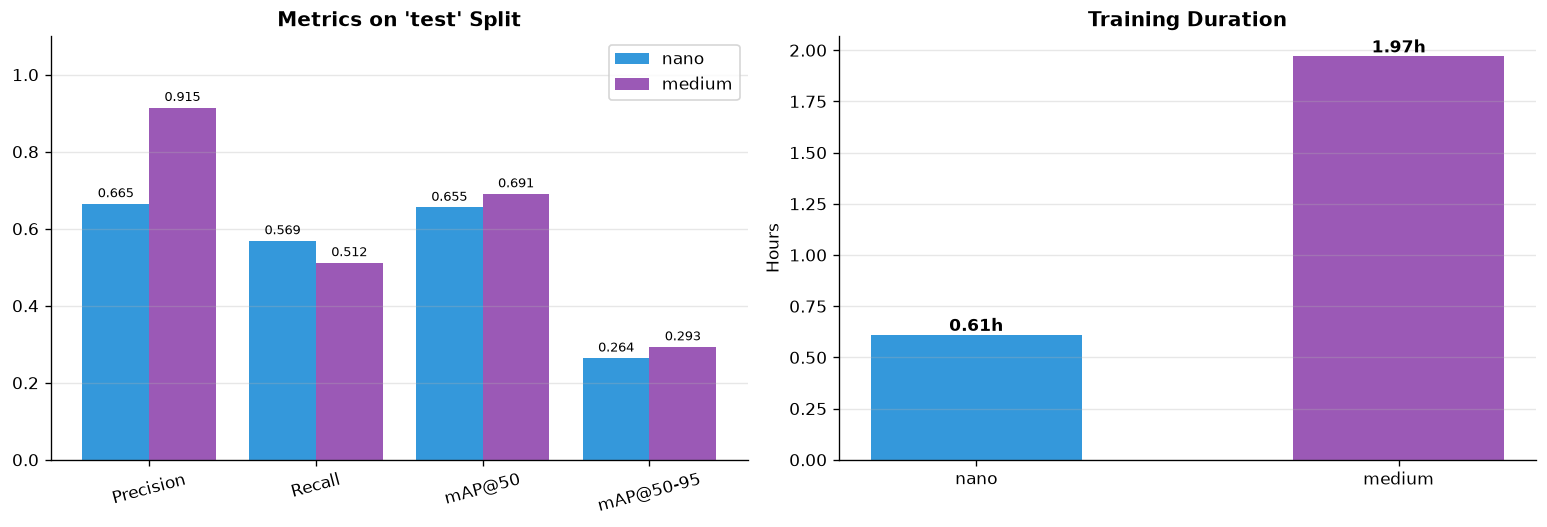

In [6]:
compare_split = "test" if f"mAP@50 (test)" in df_compare.index else "val"
metric_rows = [f"Precision ({compare_split})", f"Recall ({compare_split})",
               f"mAP@50 ({compare_split})", f"mAP@50-95 ({compare_split})"]
metric_rows = [r for r in metric_rows if r in df_compare.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
x = np.arange(len(metric_rows))
width = 0.8 / len(AVAILABLE_MODELS)
for i, label in enumerate(AVAILABLE_MODELS):
    vals = [df_compare.loc[r, label] for r in metric_rows]
    bars = ax.bar(x + i * width, vals, width, label=label, color=MODEL_COLORS.get(label))
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(x + width * (len(AVAILABLE_MODELS) - 1) / 2)
ax.set_xticklabels([r.split(" (")[0] for r in metric_rows], rotation=15)
ax.set_ylim(0, 1.1)
ax.set_title(f"Metrics on '{compare_split}' Split", fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)

ax = axes[1]
durations = [df_compare.loc["Training duration (h)", label] for label in AVAILABLE_MODELS]
bars = ax.bar(AVAILABLE_MODELS, durations, color=[MODEL_COLORS.get(l) for l in AVAILABLE_MODELS], width=0.5)
ax.bar_label(bars, fmt="%.2fh", fontweight="bold")
ax.set_ylabel("Hours")
ax.set_title("Training Duration", fontweight="bold")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(RUN_BASE / "model_comparison_3way.png", dpi=150, bbox_inches="tight")
plt.show()


**What this shows:** left, Precision/Recall/mAP50/mAP50-95 on the test split (or
val, if test is empty) for every available model side by side; right, how long each
one took to train. A model that's both cheaper to train *and* scores higher is a
clear winner; if the largest model is slowest but doesn't score highest, that's the
same "bigger isn't automatically better" pattern seen in Section 5 below.


---
## 4. Overfitting Check: Best Epoch vs. Epoch Budget


                                nano   medium
Total epochs                 81.0000  51.0000
Best epoch                   52.0000  41.0000
Best epoch (% of budget)     65.4000  82.4000
Mean gen. gap (last 10 ep.)   2.0021   1.3885


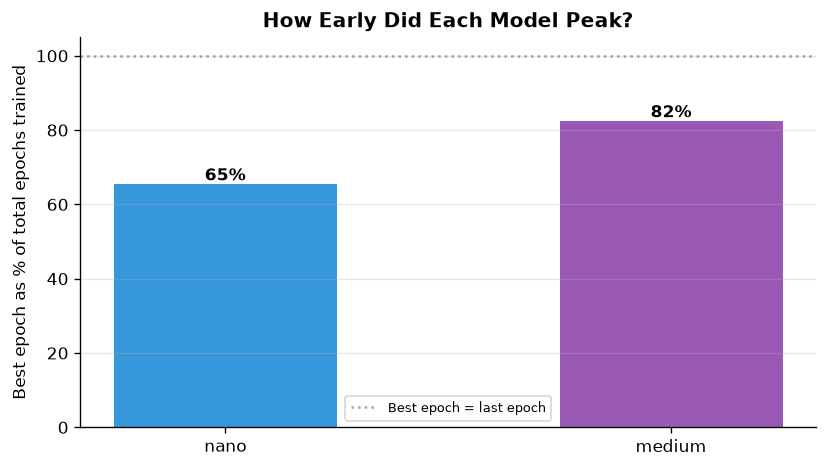

In [7]:
overfit_rows = {}
for label in AVAILABLE_MODELS:
    run_df = run_dfs[label]
    best_idx = run_df["metrics/mAP50(B)"].idxmax()
    loss_cols_tr = [c for c in ["train/box_loss", "train/cls_loss", "train/dfl_loss"] if c in run_df.columns]
    loss_cols_va = [c for c in ["val/box_loss",   "val/cls_loss",   "val/dfl_loss"]   if c in run_df.columns]
    gap = (run_df[loss_cols_va].sum(axis=1) - run_df[loss_cols_tr].sum(axis=1)).iloc[-10:].mean()
    total_epochs = int(run_df["epoch"].max()) + 1
    best_epoch = int(run_df.loc[best_idx, "epoch"])
    overfit_rows[label] = {
        "Total epochs": total_epochs,
        "Best epoch": best_epoch,
        "Best epoch (% of budget)": round(100 * (best_epoch + 1) / total_epochs, 1),
        "Mean gen. gap (last 10 ep.)": round(float(gap), 4),
    }

df_overfit = pd.DataFrame(overfit_rows)
print(df_overfit.to_string())

fig, ax = plt.subplots(figsize=(7, 4))
vals = [overfit_rows[l]["Best epoch (% of budget)"] for l in AVAILABLE_MODELS]
bars = ax.bar(AVAILABLE_MODELS, vals, color=[MODEL_COLORS.get(l) for l in AVAILABLE_MODELS], width=0.5)
ax.bar_label(bars, fmt="%.0f%%", fontweight="bold")
ax.axhline(100, color="gray", linestyle=":", alpha=0.7, label="Best epoch = last epoch")
ax.set_ylabel("Best epoch as % of total epochs trained")
ax.set_title("How Early Did Each Model Peak?", fontweight="bold")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RUN_BASE / "overfit_comparison_3way.png", dpi=150, bbox_inches="tight")
plt.show()


**What this shows:** for each model, the epoch at which validation mAP50 peaked,
expressed as a percentage of the total epochs it was allowed to train for. A value
close to 100% means the model kept improving until the end (healthy); a low value
means it peaked early and then overfit for the remaining budget — `best.pt` still
saves the good epoch, but it signals the model had more capacity than the ~240-frame
dataset could use. The "mean generalization gap" is the same val-minus-train loss
gap used in the single-model notebooks; larger = more overfitting.


---
## 5. Efficiency Trade-off: Accuracy vs. Training Cost


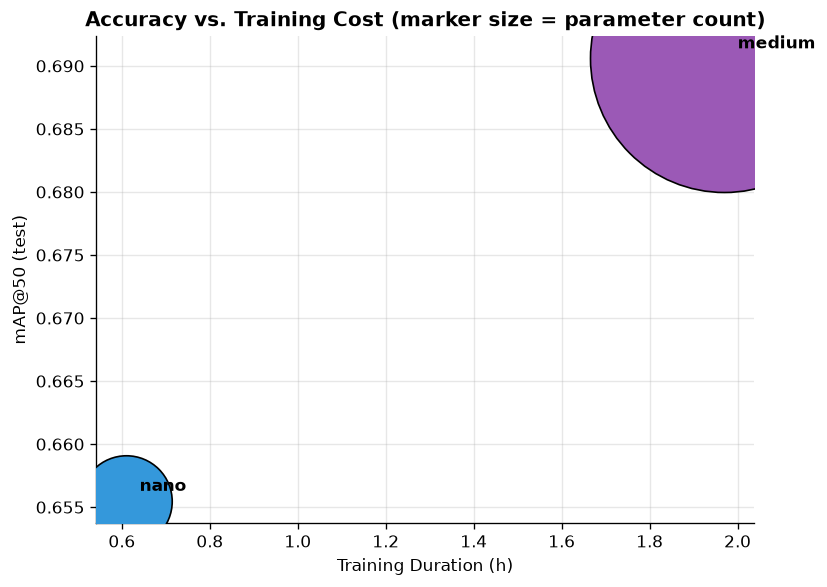

In [8]:
metric_col = f"mAP@50 ({compare_split})"
fig, ax = plt.subplots(figsize=(7, 5))
for label in AVAILABLE_MODELS:
    x = df_compare.loc["Training duration (h)", label]
    y = df_compare.loc[metric_col, label]
    size = df_compare.loc["Parameters", label] / 1000  # scale for marker size
    ax.scatter(x, y, s=max(size, 100), color=MODEL_COLORS.get(label), label=label, edgecolor="black", zorder=3)
    ax.annotate(label, (x, y), textcoords="offset points", xytext=(8, 6), fontsize=10, fontweight="bold")
ax.set_xlabel("Training Duration (h)")
ax.set_ylabel(metric_col)
ax.set_title("Accuracy vs. Training Cost (marker size = parameter count)", fontweight="bold")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RUN_BASE / "efficiency_tradeoff_3way.png", dpi=150, bbox_inches="tight")
plt.show()


**What this shows:** each model plotted by how long it took to train (x) against
how accurate it ended up (y); the marker size reflects parameter count. The ideal
model sits in the top-left (fast + accurate). If a bigger, slower marker doesn't sit
higher than a smaller, faster one, extra parameters and training time bought nothing
on this dataset — a strong signal that the bottleneck is data quantity, not model
capacity or compute.


---
## 6. TP / FP / FN Comparison (Test Split, IoU ≥ 0.5)


In [9]:
IOU_THRESHOLD = 0.5

eval_split = "test"
eval_img_dir = Path(data_cfg["path"]) / data_cfg["test"]
if not eval_img_dir.exists() or not any(eval_img_dir.glob("*.jpg")):
    eval_split = "val"
    eval_img_dir = Path(data_cfg["path"]) / data_cfg["val"]
eval_lbl_dir = Path(str(eval_img_dir).replace("images", "labels"))

def compute_iou(box_a, box_b):
    def to_xyxy(b):
        cx, cy, w, h = b
        return cx - w/2, cy - h/2, cx + w/2, cy + h/2
    ax1, ay1, ax2, ay2 = to_xyxy(box_a)
    bx1, by1, bx2, by2 = to_xyxy(box_b)
    ix1 = max(ax1, bx1); iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2); iy2 = min(ay2, by2)
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = (ax2 - ax1) * (ay2 - ay1)
    area_b = (bx2 - bx1) * (by2 - by1)
    union  = area_a + area_b - inter
    return inter / union if union > 0 else 0

def tp_fp_fn(model, img_dir, lbl_dir):
    tp_total = fp_total = fn_total = 0
    for img_path in sorted(img_dir.glob("*.jpg")):
        lbl_path = lbl_dir / (img_path.stem + ".txt")
        gt_boxes = []
        if lbl_path.exists():
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        gt_boxes.append([float(x) for x in parts[1:]])
        result = model(str(img_path), verbose=False)[0]
        pred_xywh = result.boxes.xywhn.cpu().numpy() if len(result.boxes) else []
        matched_gt = set(); matched_pred = set()
        for pi, pred in enumerate(pred_xywh):
            for gi, gt in enumerate(gt_boxes):
                if gi in matched_gt:
                    continue
                if compute_iou(pred, gt) >= IOU_THRESHOLD:
                    matched_gt.add(gi); matched_pred.add(pi)
                    break
        tp_total += len(matched_pred)
        fp_total += len(pred_xywh) - len(matched_pred)
        fn_total += len(gt_boxes) - len(matched_gt)
    return tp_total, fp_total, fn_total

tpfpfn_rows = {}
for label in AVAILABLE_MODELS:
    tp, fp, fn = tp_fp_fn(loaded_models[label], eval_img_dir, eval_lbl_dir)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    tpfpfn_rows[label] = {"TP": tp, "FP": fp, "FN": fn,
                           "Precision": round(precision, 4), "Recall": round(recall, 4), "F1": round(f1, 4)}

df_tpfpfn = pd.DataFrame(tpfpfn_rows)
print(f"TP/FP/FN analysis on split: '{eval_split}'  (IoU threshold: {IOU_THRESHOLD})")
print(df_tpfpfn.to_string())


TP/FP/FN analysis on split: 'test'  (IoU threshold: 0.5)
               nano    medium
TP         146.0000  143.0000
FP         134.0000  118.0000
FN          65.0000   68.0000
Precision    0.5214    0.5479
Recall       0.6919    0.6777
F1           0.5947    0.6059


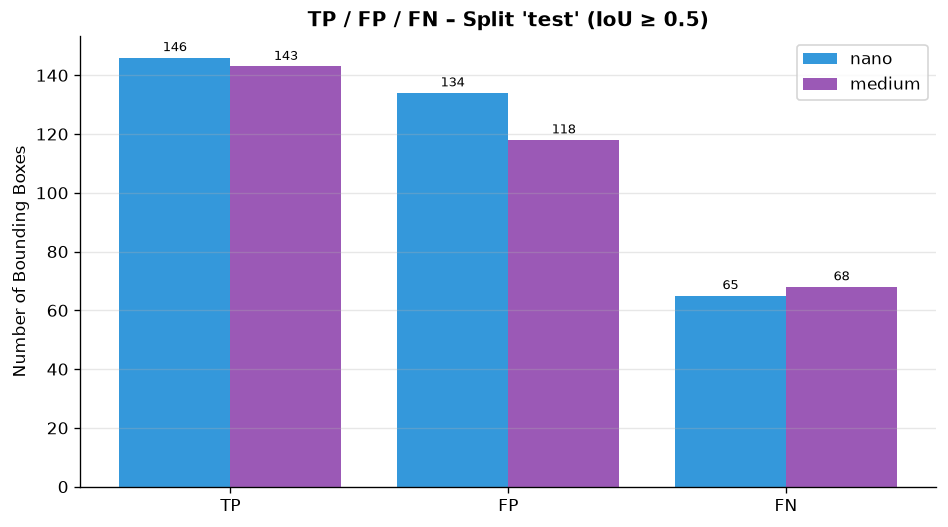

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(3)
width = 0.8 / len(AVAILABLE_MODELS)
for i, label in enumerate(AVAILABLE_MODELS):
    vals = [tpfpfn_rows[label]["TP"], tpfpfn_rows[label]["FP"], tpfpfn_rows[label]["FN"]]
    bars = ax.bar(x + i * width, vals, width, label=label, color=MODEL_COLORS.get(label))
    ax.bar_label(bars, padding=2, fontsize=8)
ax.set_xticks(x + width * (len(AVAILABLE_MODELS) - 1) / 2)
ax.set_xticklabels(["TP", "FP", "FN"])
ax.set_ylabel("Number of Bounding Boxes")
ax.set_title(f"TP / FP / FN – Split '{eval_split}' (IoU ≥ {IOU_THRESHOLD})", fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RUN_BASE / "tp_fp_fn_3way.png", dpi=150, bbox_inches="tight")
plt.show()


**What this shows:** this is a custom, independent detection count — computed here
with an explicit IoU ≥ 0.5 box-matching rule, rather than reading Ultralytics'
internal validation-only confusion matrix — aggregated over the *entire* test split
for each model. **FN** (missed dogs) is usually the more costly error for a tracking
application than **FP** (false alarms): a model with fewer FN at a similar FP count
is the more usable one in practice, even if its overall mAP is a hair lower.


---
## 7. Example Predictions Side-by-Side


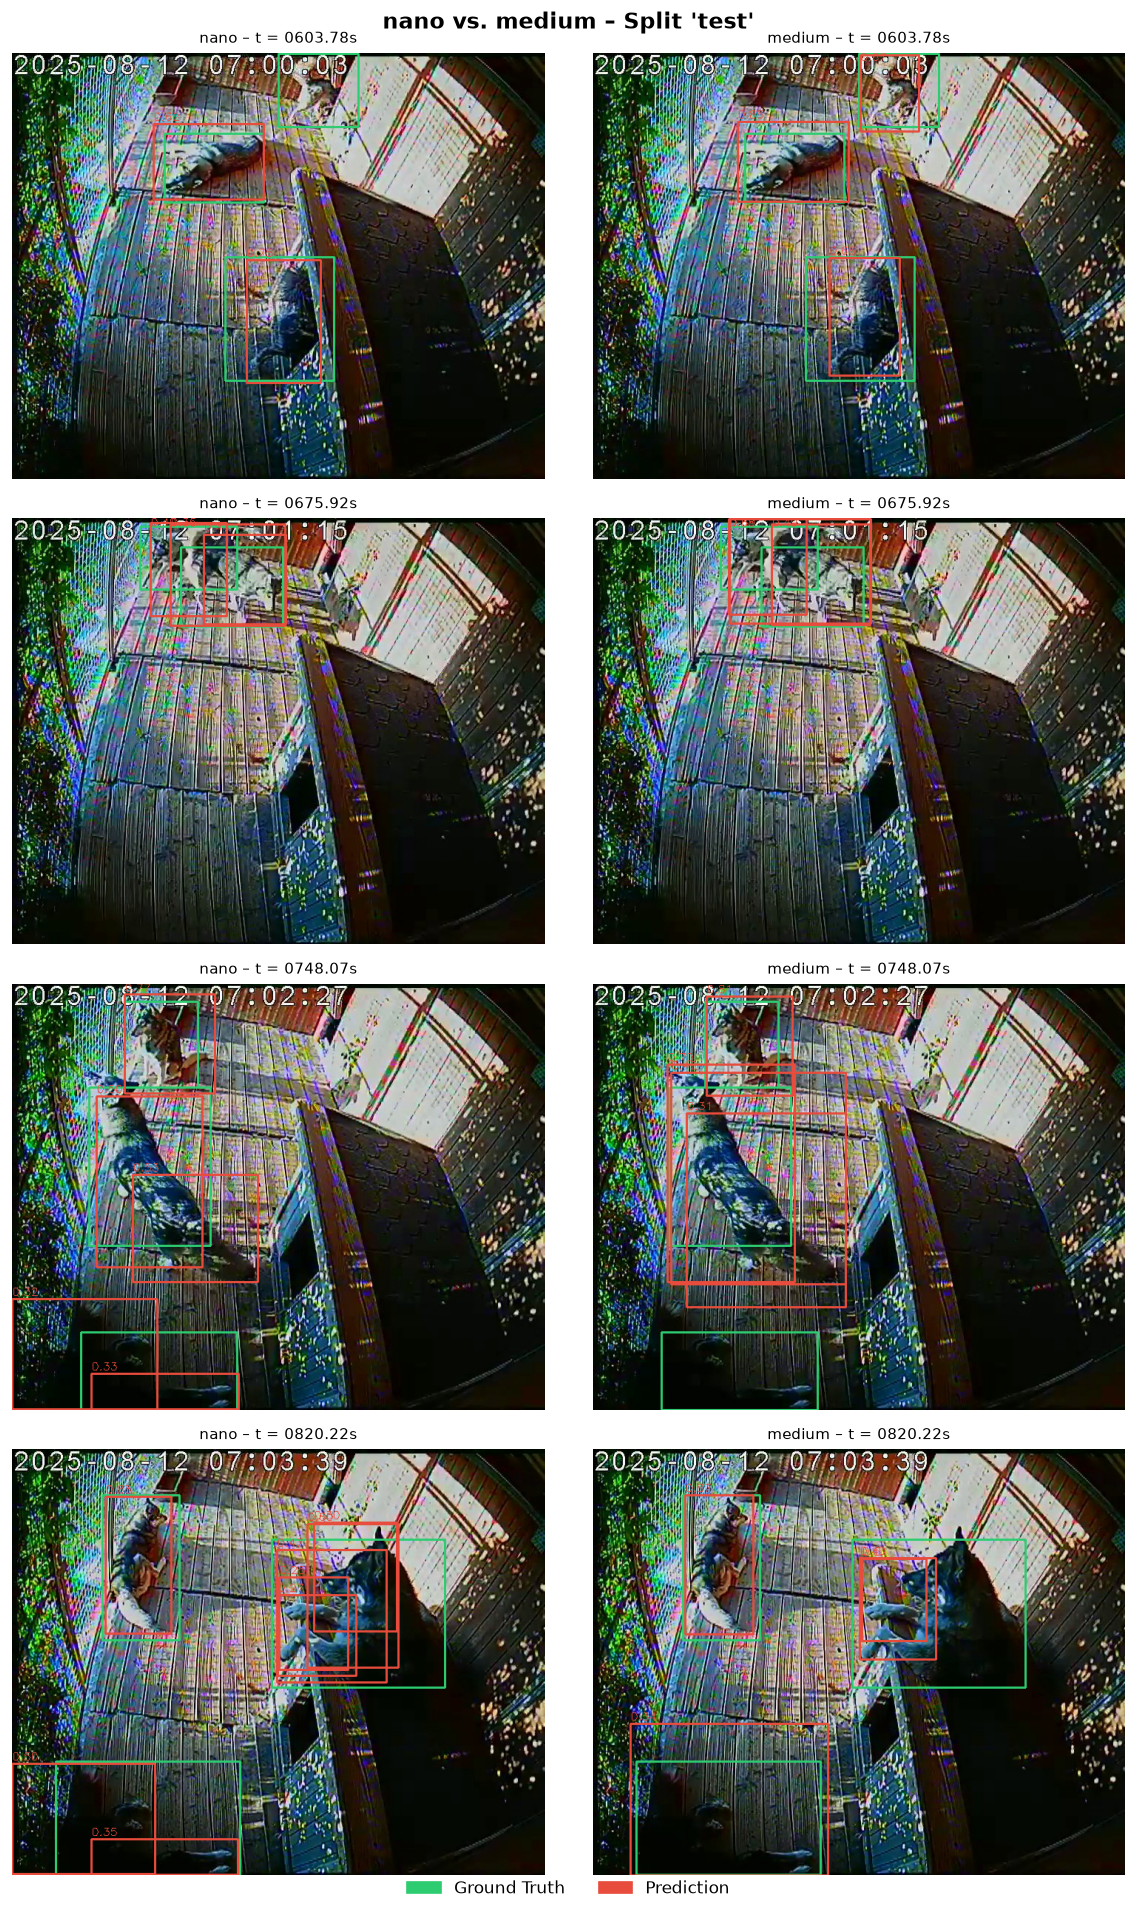

In [11]:
def draw_predictions(img_path, lbl_dir, model):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lbl_path = lbl_dir / (img_path.stem + ".txt")
    if lbl_path.exists():
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    cx, cy, bw, bh = [float(x) for x in parts[1:]]
                    x1 = int((cx - bw/2) * w); y1 = int((cy - bh/2) * h)
                    x2 = int((cx + bw/2) * w); y2 = int((cy + bh/2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (46, 204, 113), 2)
    result = model(str(img_path), verbose=False)[0]
    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().numpy())
        conf = float(box.conf[0])
        cv2.rectangle(img, (x1, y1), (x2, y2), (231, 76, 60), 2)
        cv2.putText(img, f"{conf:.2f}", (x1, max(y1 - 5, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (231, 76, 60), 1)
    return img

compare_images = sorted(eval_img_dir.glob("*.jpg"))
n_show = min(4, len(compare_images))
n_models = len(AVAILABLE_MODELS)

if n_show == 0:
    print("No images found.")
else:
    step = max(1, len(compare_images) // n_show)
    sample = [compare_images[i * step] for i in range(n_show)]

    fig, axes = plt.subplots(n_show, n_models, figsize=(5 * n_models, 4 * n_show))
    if n_show == 1:
        axes = axes.reshape(1, -1)
    fig.suptitle(f"{' vs. '.join(AVAILABLE_MODELS)} – Split '{eval_split}'", fontsize=13, fontweight="bold")

    for row_i, img_path in enumerate(sample):
        for col_i, label in enumerate(AVAILABLE_MODELS):
            ax = axes[row_i, col_i]
            img = draw_predictions(img_path, eval_lbl_dir, loaded_models[label])
            ax.imshow(img)
            time_match = img_path.stem.split("_time_")
            time_label = f"t = {time_match[-1]}s" if len(time_match) > 1 else img_path.stem[-20:]
            ax.set_title(f"{label} – {time_label}", fontsize=9)
            ax.axis("off")

    gt_patch   = mpatches.Patch(color="#2ecc71", label="Ground Truth")
    pred_patch = mpatches.Patch(color="#e74c3c", label="Prediction")
    fig.legend(handles=[gt_patch, pred_patch], loc="lower center",
               ncol=2, fontsize=10, frameon=False, bbox_to_anchor=(0.5, -0.01))
    plt.tight_layout()
    plt.savefig(RUN_BASE / "example_predictions_3way.png", dpi=150, bbox_inches="tight")
    plt.show()


**What this shows:** the same sampled frames run through every available model,
laid out side by side. **Green** = ground truth, **red** = prediction (with
confidence). Useful for spotting *qualitative* differences the aggregate metrics
hide — e.g. one model consistently missing a dog in a specific lighting condition,
or being more confident but less precise than another.


---
## 8. Summary & Verdict


In [12]:
summary_metric = f"mAP@50 ({compare_split})"
ranking = df_compare.loc[summary_metric].sort_values(ascending=False)

print("=" * 60)
print(f"  RANKING BY {summary_metric.upper()}")
print("=" * 60)
for rank, (label, val) in enumerate(ranking.items(), start=1):
    best_pct = overfit_rows[label]["Best epoch (% of budget)"]
    print(f"  {rank}. {label:<8} {summary_metric} = {val:.4f}   "
          f"(best epoch at {best_pct:.0f}% of training budget)")

winner = ranking.index[0]
print()
print(f"  → Best on '{compare_split}' split by {summary_metric}: **{winner}**")


  RANKING BY MAP@50 (TEST)
  1. medium   mAP@50 (test) = 0.6906   (best epoch at 82% of training budget)
  2. nano     mAP@50 (test) = 0.6555   (best epoch at 65% of training budget)

  → Best on 'test' split by mAP@50 (test): **medium**


**What this shows:** the models ranked purely by test-set mAP@50, alongside how
early each one peaked relative to its epoch budget (from Section 4) — a model that
tops the ranking but peaked at, say, 15% of its budget got there by overfitting
less badly than the others, not necessarily by being fundamentally better suited to
the task. Cross-reference this with Section 5 (accuracy vs. training cost) and
Section 6 (FN counts) before picking a model for deployment: the highest mAP is not
automatically the most practical choice if it comes with more missed detections or a
much higher training cost for a marginal gain.

**Actual result (nano vs. medium, trained locally; freshly re-evaluated above, not
just re-reading old logs):** contrary to an earlier draft note in `evaluate_yolo.ipynb`
claiming `nano` wins across the board, `medium`'s real best checkpoint is epoch 41 of
50 (82% of its budget, generalization gap 1.39) — not epoch 14 as previously assumed —
and it is **not** more overfit than `nano` (best epoch 52 of 80 = 65% of budget, gap
2.00). On the actual numbers: `medium` leads on mAP@50 (test) (0.691 vs. 0.656) and is
far ahead on precision (test) (0.915 vs. 0.665), at the cost of roughly 3x the training
time; `nano` only comes out slightly ahead on recall (test) (0.569 vs. 0.512) and on
the custom TP/FN count in Section 6 (fewer missed dogs: FN 65 vs. 68). So the honest
takeaway is a trade-off, not a clean win for the smaller model: `medium` is the more
accurate and more precise detector on this dataset, `nano` misses slightly fewer dogs
and trains ~3x faster. Whether `large` (43.7M params) shifts this further can only be
answered once its run folder is available locally and this notebook is re-run with all
three models present.
